# Laboratorium 04 — Splotowe sieci neuronowe (CNN)

**Cel:** wytrenować sieć MLP i prostą sieć splotową SimpleCNN na zbiorze CIFAR-10 w tych samych warunkach, a następnie porównać: accuracy, liczbę parametrów, przeuczenie i czas uczenia.

**Jak pracować z notatnikiem:**

1. Proszę ustawić środowisko GPU: **Runtime → Change runtime type → GPU**.
2. Proszę uruchamiać komórki po kolei (**Runtime → Run all** przy pierwszym przebiegu).
3. Opis kodu znajduje się w `wstep_teoretyczny.md`. Numery rozdziałów wstępu podano przy każdej sekcji.
4. Parametry eksperymentu zmienia się tylko w komórce konfiguracji (sekcja 1). Proszę zmieniać jeden parametr naraz.

*Prowadzący: dr Tomasz Cieplak / mgr inż. Patryk Marek, Rok akademicki: 2026/27*

## 0. Instalacja zależności

In [ ]:
!pip install torch torchvision matplotlib

## 1. Importy, urządzenie i konfiguracja eksperymentu

Wszystkie parametry eksperymentu są w słowniku `CFG`. Oba modele używają tej samej konfiguracji, więc porównanie jest uczciwe (`wstep_teoretyczny.md`, rozdział 9.1).

Jeżeli w wyniku widnieje `urządzenie: cpu`, proszę zmienić typ środowiska na GPU i uruchomić notatnik od początku.

In [ ]:
import copy, math, time
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Subset
import torchvision
from torchvision import transforms
import matplotlib.pyplot as plt

CFG = {
    "epochs": 10,        # budżet epok, ten sam dla obu modeli
    "lr": 1e-3,          # learning rate (Adam)
    "batch_size": 128,
    "n_val": 5000,       # rozmiar zbioru walidacyjnego wydzielonego z treningu
    "augment": False,    # augmentacja tylko na zbiorze treningowym (rozdział 7)
    "seed": 42,
}

torch.manual_seed(CFG["seed"])
device = "cuda" if torch.cuda.is_available() else "cpu"
print("PyTorch:", torch.__version__, "| urządzenie:", device)
if device == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))   # tę nazwę proszę podać w sprawozdaniu

PyTorch: 2.11.0+cu130 | urządzenie: cuda
GPU: Tesla T4


## 2. Dane: CIFAR-10 z podziałem trening / walidacja / test

CIFAR-10 to 60 000 kolorowych obrazów 32×32 w 10 klasach (3 kanały wejścia).

- **Trening** (45 000): na nim model uczy się wag.
- **Walidacja** (5 000, wydzielona z treningu): na niej wybieramy najlepszą epokę.
- **Test** (10 000): używamy go **jeden raz**, na końcu, do oceny wybranego modelu.

Zbiór treningowy jest wczytany dwukrotnie: z augmentacją (do uczenia) i bez augmentacji (do walidacji). Podział indeksów jest losowany ze stałym ziarnem, więc jest taki sam dla obu modeli (rozdział 9.2).

Pierwsze pobranie zbioru (ok. 170 MB) może trwać kilka minut.

In [ ]:
mean = (0.4914, 0.4822, 0.4465)
std  = (0.2470, 0.2435, 0.2616)
tf_eval = transforms.Compose([transforms.ToTensor(), transforms.Normalize(mean, std)])
tf_train = transforms.Compose(
    ([transforms.RandomCrop(32, padding=4), transforms.RandomHorizontalFlip()] if CFG["augment"] else [])
    + [transforms.ToTensor(), transforms.Normalize(mean, std)]
)

train_full_aug  = torchvision.datasets.CIFAR10("./data", train=True,  download=True, transform=tf_train)
train_full_eval = torchvision.datasets.CIFAR10("./data", train=True,  download=True, transform=tf_eval)
test_ds         = torchvision.datasets.CIFAR10("./data", train=False, download=True, transform=tf_eval)
classes = train_full_eval.classes

g = torch.Generator().manual_seed(CFG["seed"])
perm = torch.randperm(len(train_full_eval), generator=g).tolist()
val_idx, train_idx = perm[:CFG["n_val"]], perm[CFG["n_val"]:]
train_ds = Subset(train_full_aug, train_idx)
val_ds   = Subset(train_full_eval, val_idx)

train_dl = DataLoader(train_ds, batch_size=CFG["batch_size"], shuffle=True,  num_workers=2)
val_dl   = DataLoader(val_ds,   batch_size=256, shuffle=False, num_workers=2)
test_dl  = DataLoader(test_ds,  batch_size=256, shuffle=False, num_workers=2)
print("Klasy:", classes)
print(f"Trening: {len(train_ds)} | Walidacja: {len(val_ds)} | Test: {len(test_ds)}")

Klasy: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
Trening: 45000 | Walidacja: 5000 | Test: 10000


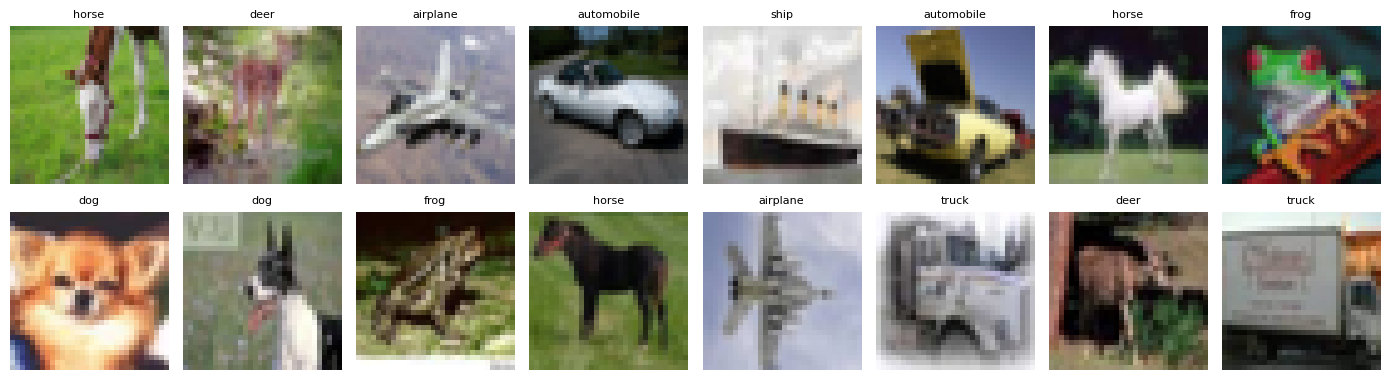

In [ ]:
# Podgląd próbek; normalizację odwracamy, aby obraz miał naturalne kolory
mean_t = torch.tensor(mean).view(3, 1, 1); std_t = torch.tensor(std).view(3, 1, 1)
def denorm(img): return (img * std_t + mean_t).clamp(0, 1).permute(1, 2, 0).numpy()

xb, yb = next(iter(train_dl))
fig, axes = plt.subplots(2, 8, figsize=(14, 4))
for ax, img, lb in zip(axes.flat, xb, yb):
    ax.imshow(denorm(img)); ax.set_title(classes[lb], fontsize=8); ax.axis("off")
plt.tight_layout(); plt.show()

## 3. Modele: MLP i SimpleCNN

**MLP** spłaszcza obraz do wektora 3072 (= 3·32·32). **SimpleCNN** ma część splotową `features` (dwa bloki: splot–BatchNorm–ReLU ×2, MaxPool) i głowicę `classifier` (warstwy gęste). Opis warstw: rozdział 6.2.

Parametry `c1`, `c2` to liczby filtrów w blokach (zakres dodatkowy zadania). Wymiar wejścia głowicy (`c2·8·8`) jest wyliczany automatycznie.

In [ ]:
class MLP(nn.Module):
    def __init__(self, in_dim=3*32*32, hidden=(512, 256), n_classes=10):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(in_dim, hidden[0]), nn.ReLU(),
            nn.Linear(hidden[0], hidden[1]), nn.ReLU(),
            nn.Linear(hidden[1], n_classes),
        )
    def forward(self, x): return self.net(x)

def block(cin, cout):
    return nn.Sequential(
        nn.Conv2d(cin, cout, 3, padding=1), nn.BatchNorm2d(cout), nn.ReLU(),
        nn.Conv2d(cout, cout, 3, padding=1), nn.BatchNorm2d(cout), nn.ReLU(),
        nn.MaxPool2d(2),                                   # H, W zmniejszone o połowę
    )

class SimpleCNN(nn.Module):
    def __init__(self, c1=32, c2=64, n_classes=10):
        super().__init__()
        self.features = nn.Sequential(block(3, c1), block(c1, c2))  # 32x32 -> 8x8
        self.classifier = nn.Sequential(
            nn.Flatten(), nn.Linear(c2*8*8, 256), nn.ReLU(),
            nn.Dropout(0.3), nn.Linear(256, n_classes),        # surowe logity, bez Softmax
        )
    def forward(self, x): return self.classifier(self.features(x))

def count_params(m): return sum(p.numel() for p in m.parameters() if p.requires_grad)

mlp_tmp, cnn_tmp = MLP(), SimpleCNN()
print(f"MLP:                   {count_params(mlp_tmp):>10,}")
print(f"CNN część splotowa:    {count_params(cnn_tmp.features):>10,}")
print(f"CNN głowica:           {count_params(cnn_tmp.classifier):>10,}")
print(f"CNN razem:             {count_params(cnn_tmp):>10,}")

MLP:                    1,707,274
CNN część splotowa:        65,952
CNN głowica:            1,051,402
CNN razem:              1,117,354


## 4. Testy kontrolne przed treningiem

Trzy szybkie testy z rozdziału 8.3. Jeżeli któryś test nie daje oczekiwanego wyniku, proszę szukać błędu w kodzie, zanim uruchomią Państwo pełny trening.

1. **Kształty:** wyjście modelu ma kształt `(N, 10)`.
2. **Strata na starcie:** ok. `ln(10) ≈ 2,30`.
3. **Przeuczenie jednej paczki:** strata spada blisko zera w ok. 100 krokach.

In [ ]:
# Test 1: przepływ kształtów przez SimpleCNN
x = torch.randn(4, 3, 32, 32)
for name, layer in cnn_tmp.features.named_children():
    x = layer(x); print("blok", name, tuple(x.shape))
print("logity", tuple(cnn_tmp.classifier(x).shape))

# Test 2: strata na starcie
crit = nn.CrossEntropyLoss()
xb, yb = next(iter(train_dl))
for name, m in [("MLP", MLP()), ("CNN", SimpleCNN())]:
    m = m.to(device).eval()
    with torch.no_grad():
        print(f"{name}: strata na starcie {crit(m(xb.to(device)), yb.to(device)).item():.3f}"
              f" (oczekiwane ok. {math.log(10):.3f})")

# Test 3: przeuczenie jednej paczki (32 obrazy)
m = SimpleCNN().to(device); opt = torch.optim.Adam(m.parameters(), lr=1e-3)
x32, y32 = xb[:32].to(device), yb[:32].to(device)
m.train()
for step in range(101):
    opt.zero_grad(); loss = crit(m(x32), y32); loss.backward(); opt.step()
    if step % 25 == 0: print(f"krok {step:3d} | strata {loss.item():.4f}")

blok 0 (4, 32, 16, 16)
blok 1 (4, 64, 8, 8)
logity (4, 10)
MLP: strata na starcie 2.309 (oczekiwane ok. 2.303)
CNN: strata na starcie 2.303 (oczekiwane ok. 2.303)
krok   0 | strata 2.3737
krok  25 | strata 0.0030
krok  50 | strata 0.0002
krok  75 | strata 0.0002
krok 100 | strata 0.0001


## 5. Funkcje treningu i ewaluacji

- `train_one_epoch` — jedna epoka uczenia; zwraca średnią stratę treningową.
- `evaluate` — strata i accuracy na podanym zbiorze, w trybie `model.eval()` i bez gradientów.
- `fit` — pełny trening. Po każdej epoce liczy stratę i accuracy na treningu i walidacji. Zapamiętuje wagi z epoki o **najwyższej accuracy walidacyjnej**. Zbioru testowego `fit` nie używa.

Czas uczenia (`train_time`) obejmuje tylko pętle treningowe. Czas ewaluacji jest mierzony osobno. Przed odczytem czasu wywołujemy `torch.cuda.synchronize()`, ponieważ obliczenia GPU są asynchroniczne (rozdział 9.3).

Accuracy treningowa jest liczona osobnym przejściem przez zbiór treningowy w trybie `eval` (bez dropoutu). Dzięki temu przerwa train–walidacja jest mierzona tak samo dla obu zbiorów.

In [ ]:
def sync():
    if device == "cuda": torch.cuda.synchronize()

def train_one_epoch(model, dl, opt, crit):
    model.train(); s = n = 0
    for xb, yb in dl:
        xb, yb = xb.to(device), yb.to(device)
        opt.zero_grad(); loss = crit(model(xb), yb); loss.backward(); opt.step()
        s += loss.item() * yb.size(0); n += yb.size(0)
    return s / n

@torch.no_grad()
def evaluate(model, dl, crit):
    model.eval(); s = c = n = 0
    for xb, yb in dl:
        xb, yb = xb.to(device), yb.to(device)
        out = model(xb)
        s += crit(out, yb).item() * yb.size(0)
        c += (out.argmax(1) == yb).sum().item(); n += yb.size(0)
    return s / n, c / n

# Ewaluacja na treningu: te same obrazy treningowe, ale bez augmentacji
train_eval_dl = DataLoader(Subset(train_full_eval, train_idx), batch_size=256,
                           shuffle=False, num_workers=2)

def fit(model, cfg=CFG):
    torch.manual_seed(cfg["seed"])
    model = model.to(device)
    crit = nn.CrossEntropyLoss()
    opt = torch.optim.Adam(model.parameters(), lr=cfg["lr"])
    hist = {k: [] for k in ["train_loss", "train_acc", "val_loss", "val_acc"]}
    best = {"val_acc": -1.0, "epoch": 0, "state": None}
    train_time = eval_time = 0.0
    for epoch in range(1, cfg["epochs"] + 1):
        sync(); t0 = time.time()
        train_one_epoch(model, train_dl, opt, crit)
        sync(); t1 = time.time()
        tr_loss, tr_acc = evaluate(model, train_eval_dl, crit)
        va_loss, va_acc = evaluate(model, val_dl, crit)
        sync(); t2 = time.time()
        train_time += t1 - t0; eval_time += t2 - t1
        for k, v in zip(hist, [tr_loss, tr_acc, va_loss, va_acc]): hist[k].append(v)
        if va_acc > best["val_acc"]:
            best = {"val_acc": va_acc, "epoch": epoch, "state": copy.deepcopy(model.state_dict())}
        print(f"  epoka {epoch:2d} | strata tr {tr_loss:.3f} wal {va_loss:.3f}"
              f" | acc tr {tr_acc*100:5.2f}% wal {va_acc*100:5.2f}%")
    model.load_state_dict(best["state"])      # przywracamy wagi z najlepszej epoki walidacyjnej
    return {"model": model, "hist": hist, "best": best,
            "train_time": train_time, "eval_time": eval_time}

## 6. Trening: MLP i SimpleCNN

Oba modele uczymy z tą samą konfiguracją `CFG`. Na GPU w Colab każdy trening trwa zwykle kilka minut.

Uruchomienie tej komórki ponownie tworzy **nowe** modele od początku.

In [ ]:
print("== MLP ==")
res_mlp = fit(MLP())
print("\n== SimpleCNN ==")
res_cnn = fit(SimpleCNN())

== MLP ==
  epoka  1 | strata tr 1.448 wal 1.523 | acc tr 48.92% wal 46.26%
  epoka  2 | strata tr 1.346 wal 1.471 | acc tr 52.58% wal 48.88%
  epoka  3 | strata tr 1.210 wal 1.402 | acc tr 57.28% wal 51.70%
  epoka  4 | strata tr 1.155 wal 1.421 | acc tr 59.34% wal 50.54%
  epoka  5 | strata tr 1.049 wal 1.372 | acc tr 62.73% wal 52.70%
  epoka  6 | strata tr 0.952 wal 1.385 | acc tr 66.44% wal 52.90%
  epoka  7 | strata tr 0.886 wal 1.417 | acc tr 68.70% wal 53.50%
  epoka  8 | strata tr 0.836 wal 1.464 | acc tr 70.59% wal 53.54%
  epoka  9 | strata tr 0.774 wal 1.532 | acc tr 72.58% wal 52.30%
  epoka 10 | strata tr 0.697 wal 1.569 | acc tr 75.43% wal 53.36%

== SimpleCNN ==
  epoka  1 | strata tr 1.004 wal 1.023 | acc tr 64.46% wal 63.70%
  epoka  2 | strata tr 0.829 wal 0.876 | acc tr 70.66% wal 68.68%
  epoka  3 | strata tr 0.656 wal 0.738 | acc tr 76.72% wal 73.78%
  epoka  4 | strata tr 0.578 wal 0.690 | acc tr 79.56% wal 75.66%
  epoka  5 | strata tr 0.525 wal 0.684 | acc tr 8

## 7. Końcowa ocena na zbiorze testowym

Każdy model oceniamy **jeden raz**, z wagami z epoki o najwyższej accuracy walidacyjnej. Wyniku testowego nie używamy do wyboru epoki ani konfiguracji.

In [ ]:
crit = nn.CrossEntropyLoss()
rows = []
for name, r in [("MLP", res_mlp), ("CNN", res_cnn)]:
    m, h, b = r["model"], r["hist"], r["best"]
    _, test_acc = evaluate(m, test_dl, crit)
    i = b["epoch"] - 1
    rows.append((name, count_params(m), b["epoch"], h["train_acc"][i], b["val_acc"],
                 h["train_acc"][i] - b["val_acc"], test_acc, r["train_time"]))

print(f"{'model':5} | {'parametry':>10} | {'epoka':>5} | {'acc tr':>7} | {'acc wal':>7} |"
      f" {'przerwa':>7} | {'acc test':>8} | {'czas tr [s]':>11}")
print("-" * 86)
for n, p, e, tr, va, gap, te, t in rows:
    print(f"{n:5} | {p:>10,} | {e:>5} | {tr*100:6.2f}% | {va*100:6.2f}% |"
          f" {gap*100:6.2f}% | {te*100:7.2f}% | {t:>11.1f}")
print(f"\nCNN: część splotowa {count_params(res_cnn['model'].features):,},"
      f" głowica {count_params(res_cnn['model'].classifier):,}")
print("Klasyfikator losowy: 10.00%")

model |  parametry | epoka |  acc tr | acc wal | przerwa | acc test | czas tr [s]
--------------------------------------------------------------------------------------
MLP   |  1,707,274 |     8 |  70.59% |  53.54% |  17.05% |   52.03% |       102.2
CNN   |  1,117,354 |    10 |  89.54% |  79.08% |  10.46% |   78.68% |       117.8

CNN: część splotowa 65,952, głowica 1,051,402
Klasyfikator losowy: 10.00%


## 8. Krzywe uczenia

Lewy wykres: strata, prawy: accuracy. Linie ciągłe to trening, przerywane to walidacja. Pionowa kropkowana linia oznacza epokę wybraną na walidacji.

Interpretacja krzywych: tabela w rozdziale 8.2 wstępu. Duża i rosnąca przerwa między linią ciągłą a przerywaną oznacza przeuczenie.

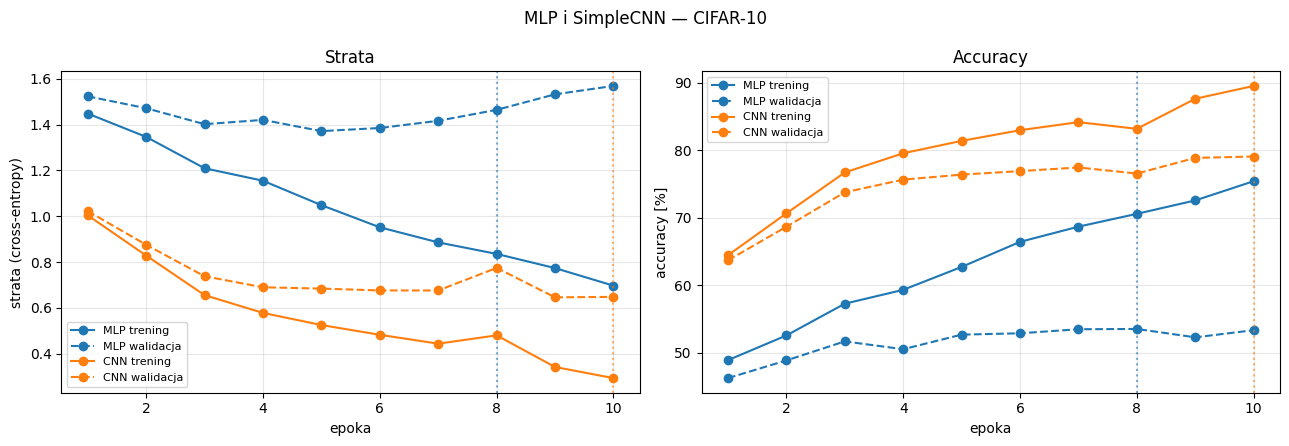

In [ ]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))
for name, r, color in [("MLP", res_mlp, "tab:blue"), ("CNN", res_cnn, "tab:orange")]:
    h = r["hist"]; ep = range(1, len(h["train_loss"]) + 1)
    ax1.plot(ep, h["train_loss"], "-o", color=color, label=f"{name} trening")
    ax1.plot(ep, h["val_loss"], "--o", color=color, label=f"{name} walidacja")
    ax2.plot(ep, [a*100 for a in h["train_acc"]], "-o", color=color, label=f"{name} trening")
    ax2.plot(ep, [a*100 for a in h["val_acc"]], "--o", color=color, label=f"{name} walidacja")
    for ax in (ax1, ax2): ax.axvline(r["best"]["epoch"], color=color, ls=":", alpha=0.6)
ax1.set(xlabel="epoka", ylabel="strata (cross-entropy)", title="Strata")
ax2.set(xlabel="epoka", ylabel="accuracy [%]", title="Accuracy")
for ax in (ax1, ax2): ax.grid(alpha=0.3); ax.legend(fontsize=8)
plt.suptitle("MLP i SimpleCNN — CIFAR-10"); plt.tight_layout(); plt.show()

## 9. Mapy cech pierwszej i głębszej warstwy splotowej

Jeden obraz testowy przechodzi przez:

- pierwszą warstwę splotową `features[0][0]` (filtry 3×3 na obrazie RGB, mapy 32×32),
- pierwszą warstwę splotową drugiego bloku `features[1][0]` (wejście: wyjście całego pierwszego bloku, mapy 16×16).

Pokazujemy ReLU wyjścia samego splotu, bez BatchNorm. To podgląd reakcji filtrów, a nie etykiety klas (rozdział 6.5).

mapy warstwy 1: (32, 32, 32) | mapy warstwy głębszej: (64, 16, 16)


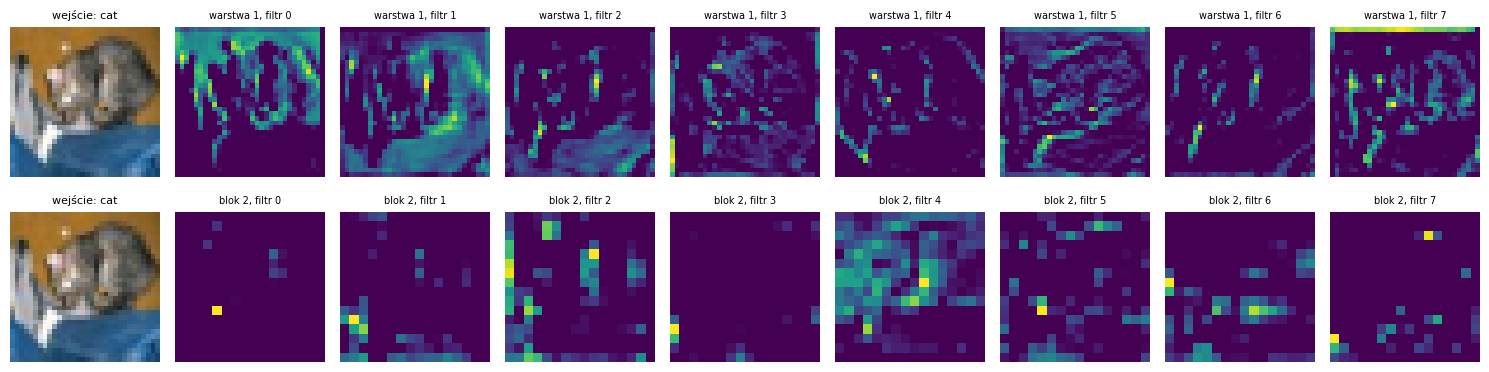

In [ ]:
cnn = res_cnn["model"].eval()
img, label = test_ds[0]
x = img.unsqueeze(0).to(device)                       # [3,32,32] -> [1,3,32,32]
with torch.no_grad():
    maps1 = torch.relu(cnn.features[0][0](x))[0].cpu()          # [32, 32, 32]
    after_block1 = cnn.features[0](x)                           # [1, 32, 16, 16]
    maps2 = torch.relu(cnn.features[1][0](after_block1))[0].cpu()  # [64, 16, 16]
print("mapy warstwy 1:", tuple(maps1.shape), "| mapy warstwy głębszej:", tuple(maps2.shape))

fig, axes = plt.subplots(2, 9, figsize=(15, 4))
for row, (maps, title) in enumerate([(maps1, "warstwa 1"), (maps2, "blok 2")]):
    axes[row, 0].imshow(denorm(img)); axes[row, 0].axis("off")
    axes[row, 0].set_title(f"wejście: {classes[label]}", fontsize=8)
    for i, ax in enumerate(axes[row, 1:]):
        ax.imshow(maps[i], cmap="viridis"); ax.axis("off")
        ax.set_title(f"{title}, filtr {i}", fontsize=7)
plt.tight_layout(); plt.show()

## 10. Zakres dodatkowy: wpływ liczby filtrów

Komórka trenuje SimpleCNN z różną liczbą filtrów w blokach. Domyślnie jest wyłączona (`RUN_EXTRA = False`), ponieważ trzy treningi trwają kilkanaście minut. Wyniki porównujemy na **walidacji**.

In [ ]:
RUN_EXTRA = False

if RUN_EXTRA:
    extra = []
    for c1, c2 in [(16, 32), (32, 64), (64, 128)]:
        print(f"\n== SimpleCNN c1={c1}, c2={c2} ==")
        r = fit(SimpleCNN(c1, c2))
        extra.append((c1, c2, count_params(r["model"]), r["best"]["val_acc"], r["train_time"]))
    print(f"\n{'c1/c2':>8} | {'parametry':>10} | {'acc wal':>7} | {'czas tr [s]':>11}")
    for c1, c2, p, va, t in extra:
        print(f"{f'{c1}/{c2}':>8} | {p:>10,} | {va*100:6.2f}% | {t:>11.1f}")

## 11. Podsumowanie i lista kontrolna do sprawozdania

Proszę sprawdzić, czy sprawozdanie zawiera:

- tabelę z sekcji 7 (parametry, epoka, accuracy treningowa, walidacyjna i testowa, przerwa, czas) oraz nazwę GPU z sekcji 1,
- wykres z sekcji 8 (strata i accuracy, trening i walidacja),
- komentarz, który wynika z Państwa danych: liczba parametrów części splotowej i głowicy, własności splotu, przeuczenie każdego modelu,
- konfigurację `CFG` użytą w eksperymencie.

Jeżeli wyniki odbiegają od oczekiwań, proszę skorzystać z procedury z rozdziału 8.5 wstępu.

Warstwy splotowe szczegółowo: Laboratorium 05. Pooling: Laboratorium 06. Treść zadania: `zadanie.md`.

*Prowadzący: dr Tomasz Cieplak / mgr inż. Patryk Marek, Rok akademicki: 2026/27*